dx=1.0000, dt=0.1333, number_of_steps=1500, simulation_time=200.0 s


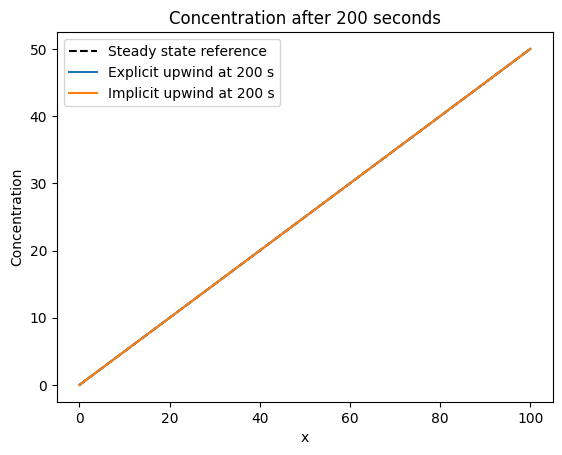

CFL=0.80
Maximum error at 200 seconds versus steady state: explicit=0.000, implicit=0.000
Implicit iterations per time step: min=1, max=28, mean=4.2

Calculation time for the 200-second simulation after Numba compilation (5 repetitions):
    steady state: best=   0.001 ms, mean=   0.003 ms
 explicit upwind: best=   0.667 ms, mean=   0.780 ms
 implicit upwind: best=   3.562 ms, mean=   4.185 ms


In [50]:
# Steady-State vs. Explicit vs. Implicit Solvers
# Solve dC/dt + u dC/dx = S with C(0, t) = 0.
import timeit

import matplotlib.pyplot as plt
import numpy as np
from numba import njit

# Create the spatial grid and physical parameters.
x = np.linspace(0, 100, 101)
velocity = np.ones_like(x) * 6  # constant velocity of 6 m/s
source = np.ones_like(x) * 3  # concentration units per second


@njit
def steady_state_solution(x, velocity, source, inlet_concentration=0.0):
    """Calculate the steady solution of u dC/dx = S with an inlet value."""
    concentration = np.empty_like(x)
    concentration[0] = inlet_concentration

    for i in range(1, len(x)):
        concentration[i] = concentration[i - 1] + (
            source[i] / velocity[i - 1]
        ) * (x[i] - x[i - 1])

    return concentration


# Calculate the steady-state profile through the callable solver.
concentration = steady_state_solution(x, velocity, source)

# Use a CFL-safe time step and run both transient schemes for the selected timeframe.
dx = x[1] - x[0]
cfl = 0.8
simulation_time = 200.0
maximum_dt = cfl * dx / np.max(velocity)
number_of_steps = int(np.ceil(simulation_time / maximum_dt))
dt = simulation_time / number_of_steps

print(
    f"dx={dx:.4f}, dt={dt:.4f}, number_of_steps={number_of_steps}, "
    f"simulation_time={number_of_steps * dt:.1f} s"
)


@njit
def explicit_upwind(concentration, number_of_steps, velocity, source, dt, dx):
    concentration = concentration.copy()
    history = np.empty((number_of_steps + 1, len(concentration)))
    history[0] = concentration
    courant_number = velocity * dt / dx

    for time_step in range(number_of_steps):
        previous = concentration.copy()
        concentration[0] = 0.0
        concentration[1:] = (
            previous[1:]
            - courant_number[1:] * (previous[1:] - previous[:-1])
            + dt * source[1:]
        )
        history[time_step + 1] = concentration

    return concentration, history


@njit
def implicit_upwind(
    concentration,
    number_of_steps,
    velocity,
    source,
    dt,
    dx,
    tolerance=1.0e-10,
    maximum_iterations=100,
):
    concentration = concentration.copy()
    history = np.empty((number_of_steps + 1, len(concentration)))
    history[0] = concentration
    courant_number = velocity * dt / dx
    iteration_counts = np.empty(number_of_steps, dtype=np.int64)

    for time_step in range(number_of_steps):
        previous = concentration.copy()
        iterate = previous.copy()

        for iteration in range(1, maximum_iterations + 1):
            updated = iterate.copy()
            updated[0] = 0.0
            updated[1:] = (
                previous[1:]
                + dt * source[1:]
                + courant_number[1:] * iterate[:-1]
            ) / (1.0 + courant_number[1:])

            if np.max(np.abs(updated - iterate)) < tolerance:
                iterate = updated
                break
            iterate = updated
        else:
            raise RuntimeError(
                "Implicit solver did not converge within "
                f"{maximum_iterations} iterations"
            )

        concentration = iterate
        iteration_counts[time_step] = iteration
        history[time_step + 1] = concentration

    return concentration, history, iteration_counts


initial_concentration = np.zeros_like(x)
explicit_concentration, explicit_history = explicit_upwind(
    initial_concentration, number_of_steps, velocity, source, dt, dx
)
implicit_concentration, implicit_history, implicit_iteration_counts = implicit_upwind(
    initial_concentration, number_of_steps, velocity, source, dt, dx
)

# Both transient solutions are evaluated at the selected timeframe against the steady reference.
plt.figure()
plt.plot(x, concentration, "k--", label="Steady state reference")
plt.plot(
    x,
    explicit_concentration,
    label=f"Explicit upwind at {simulation_time:.0f} s",
)
plt.plot(
    x,
    implicit_concentration,
    label=f"Implicit upwind at {simulation_time:.0f} s",
)
plt.xlabel("x")
plt.ylabel("Concentration")
plt.title(f"Concentration after {simulation_time:.0f} seconds")
plt.legend()
plt.show()


def measure_runtime(solver_call, repetitions=5):
    """Return minimum and mean runtime for repeated compiled solver calls."""
    runtimes = timeit.repeat(solver_call, repeat=repetitions, number=1)
    return min(runtimes), np.mean(runtimes)


# Warm up each compiled function so Numba compilation is excluded from timings.
steady_state_solution(x, velocity, source)
explicit_upwind(initial_concentration, number_of_steps, velocity, source, dt, dx)
implicit_upwind(initial_concentration, number_of_steps, velocity, source, dt, dx)

# Time only the compiled solver calls, excluding compilation, plotting, and formatting.
runtime_calls = {
    "steady state": lambda: steady_state_solution(x, velocity, source),
    "explicit upwind": lambda: explicit_upwind(
        initial_concentration, number_of_steps, velocity, source, dt, dx
    ),
    "implicit upwind": lambda: implicit_upwind(
        initial_concentration, number_of_steps, velocity, source, dt, dx
    ),
}
runtimes = {
    name: measure_runtime(solver_call)
    for name, solver_call in runtime_calls.items()
}

print(f"CFL={np.max(velocity) * dt / dx:.2f}")
print(
    f"Maximum error at {simulation_time:.0f} seconds versus steady state: "
    f"explicit={np.max(np.abs(explicit_concentration - concentration)):.3f}, "
    f"implicit={np.max(np.abs(implicit_concentration - concentration)):.3f}"
)
print(
    "Implicit iterations per time step: "
    f"min={implicit_iteration_counts.min()}, "
    f"max={implicit_iteration_counts.max()}, "
    f"mean={implicit_iteration_counts.mean():.1f}"
)

print(
    f"\nCalculation time for the {simulation_time:.0f}-second simulation "
    "after Numba compilation (5 repetitions):"
)
for name, (minimum, mean) in sorted(runtimes.items(), key=lambda item: item[1][0]):
    print(f"{name:>16}: best={minimum * 1e3:8.3f} ms, mean={mean * 1e3:8.3f} ms")
